#### Requirements

In [1]:
import pandas as pd
import numpy as np
from random_strategy_benchmark.backtester import backtester, backtester_v2, calculate_return
from random_strategy_benchmark.summary import summary
from random_strategy_benchmark.strategies import run_momentum_strategy

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252
returns_array = np.array(returns)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_position = momentum_df["position"]

#### Cyclic-Shifting Exploration

In [4]:
x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

group_1 = []
group_2 = []

for i in range(lookback + 1, len(momentum_position)):

    if i < x:
        group_1.append(momentum_position.iloc[i])
    elif i >= x:
        group_2.append(momentum_position.iloc[i])

In [5]:
sequence = []

sequence.extend(group_2)
sequence.extend(group_1)

sequence.append(np.nan)
random_signal = ([np.nan] * lookback) + sequence

sequence


[np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float6

In [6]:
random_df, random_result = backtester(returns, random_signal, 0.001)
random_df.iloc[250:260]

,return,signal,position,strategy_return,transaction_cost,net_strategy_return,equity,running_peak,drawdown
250,0.003047,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
251,-0.018929,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
252,-0.018104,1.0,NaN,NaN,0.000,NaN,1.000000,1.000000,0.000000
253,0.048035,1.0,1.0,0.048035,0.001,0.047035,1.047035,1.047035,0.000000
254,-0.010764,1.0,1.0,-0.010764,0.000,-0.010764,1.035765,1.047035,-0.010764
255,-0.032643,1.0,1.0,-0.032643,0.000,-0.032643,1.001954,1.047035,-0.043056
256,0.007741,1.0,1.0,0.007741,0.000,0.007741,1.009710,1.047035,-0.035648
257,-0.002641,1.0,1.0,-0.002641,0.000,-0.002641,1.007044,1.047035,-0.038194
258,0.017570,1.0,1.0,0.017570,0.000,0.017570,1.024738,1.047035,-0.021296
259,0.000946,1.0,1.0,0.000946,0.000,0.000946,1.025707,1.047035,-0.020370


In [7]:
one_count = 0
zero_count = 0

for i in range(len(sequence)):
    if sequence[i] == 1:
        one_count += 1
    elif sequence[i] == 0:
        zero_count += 1

print(one_count)
print(zero_count)

5008
1452


In [8]:
run_boundaries = []

for i in range(1, len(sequence)):
    if sequence[i] != sequence[i - 1]:
        run_boundaries.append(i)

len(run_boundaries)

91

#### Cyclic-Shifting Random Strategy

In [9]:
def generate_random_signal_v6(momentum_position, lookback):

    x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

    group_1 = momentum_position.iloc[lookback + 1: x]
    group_2 = momentum_position.iloc[x:]

    sequence = []

    sequence.extend(group_2)
    sequence.extend(group_1)

    sequence.append(np.nan)
    random_signal = ([np.nan] * lookback) + sequence  

    return random_signal 

In [10]:
def run_simulation_v6(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v6(momentum_position, lookback)
        random_result = backtester_v2(returns_array, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [11]:
np.random.seed(44)

simulation_output = run_simulation_v6(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.640932,0.051702,0.177454,0.372883,-0.551895,0.093680,0.775232,91
1,3.560960,0.060985,0.174772,0.426198,-0.568759,0.107225,0.775232,91
2,4.075854,0.065421,0.172471,0.453732,-0.605594,0.108028,0.775232,91
3,11.767719,0.104457,0.154446,0.720748,-0.337173,0.309802,0.775232,91
4,3.817706,0.063254,0.173120,0.440884,-0.543644,0.116352,0.775232,91
...,...,...,...,...,...,...,...,...
99995,2.334953,0.048106,0.175325,0.355717,-0.556776,0.086402,0.775232,90
99996,3.180478,0.057386,0.176889,0.403943,-0.557243,0.102982,0.775232,90
99997,2.297147,0.047640,0.162047,0.368266,-0.460290,0.103501,0.775232,91
99998,6.238620,0.080276,0.154416,0.577465,-0.363894,0.220602,0.775232,91


Mean Sharpe: 0.4735
Median Sharpe: 0.44237
Max Sharpe: 1.18105
P Value: 0.11017
Avg Trades: 90.76216
Avg Time Invested: 0.77523
Number Of Simulations: 100000


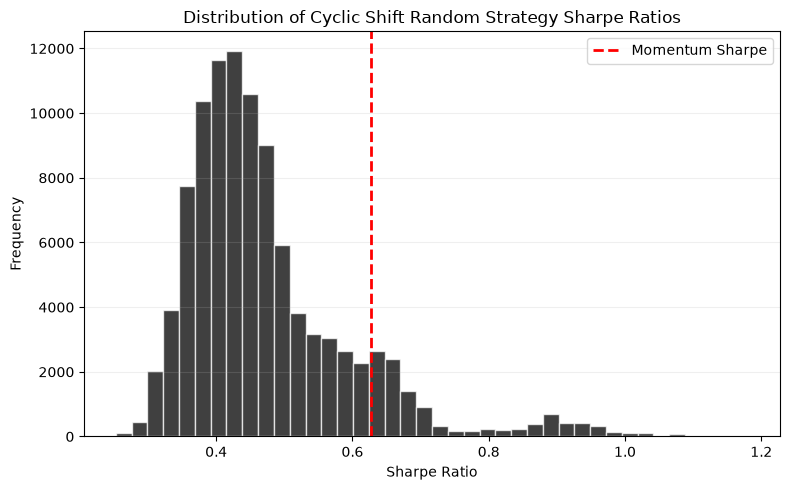

In [12]:
cycle_shifting_summary = summary(simulation_df, momentum_results, "cyclic_shift_random_strategy")